## Problem Statement

You’re an engineer supporting a bank’s customer-service team. Customers send messages about missing cards, unrecognised payments, delayed transfers and identity checks. Before anyone can resolve the issue, the message needs to reach the right workflow.

A customer might write:

> “The money has left my account, but the person I sent it to hasn’t received it.”

Is the transfer still pending, or has it completed without reaching the recipient? Similar wording can describe different problems, and choosing the wrong category can delay resolution.

**BankRoute classifies each customer message into one of ten banking intents.** A downstream application could use that label to select a queue or workflow.

| Intent label | Banking issue |
|---|---|
| `card_arrival` | A newly ordered card has not arrived |
| `lost_or_stolen_card` | An existing card is lost or stolen |
| `card_payment_not_recognised` | The customer does not recognise a card payment |
| `declined_card_payment` | A card payment was rejected |
| `pending_card_payment` | A card payment remains pending |
| `transaction_charged_twice` | The customer reports a duplicate charge |
| `pending_transfer` | A transfer is still pending |
| `transfer_not_received_by_recipient` | The intended recipient has not received a transfer |
| `unable_to_verify_identity` | The customer cannot complete identity verification |
| `verify_source_of_funds` | The customer needs help with source-of-funds verification |

The model returns **only the intent label**. For example:

**Customer message:** “I lost my bank card and cannot find it anywhere.”  
**Model output:** `lost_or_stolen_card`

This notebook implements and evaluates the classifier. Connecting its predictions to queues, webhooks or banking systems is a separate integration step. The model does not answer customer questions, block cards, approve transfers or make identity-verification decisions.

### Why fine-tune a smaller model?

This is a narrowly defined classification task with a fixed set of outputs. Instead of generating a detailed conversational answer, the model needs to recognise the issue and follow a strict label-only response format.

BankRoute fine-tunes **Qwen3-1.7B-Base using LoRA**, which learns a small set of parameter updates while keeping the original model weights frozen during training. Approximately **0.5% of the total parameters** were trainable in this run.

On the same 400 official test messages, exact-label accuracy increased from **39.0% for the original model to 93.5% for the fine-tuned model**. This demonstrates an improvement for the selected banking task. Deployment cost and inference latency were not benchmarked.

### Why not just use keywords?

Banking intents often share the same vocabulary:

- “My card hasn’t arrived” concerns **card arrival**, while “I can’t find my card” concerns a **lost card**.
- “My payment was declined” differs from “My payment is still pending.”
- “My transfer is pending” differs from “The recipient hasn’t received my transfer.”

A keyword such as “card,” “payment” or “transfer” is insufficient to identify the issue. The classifier must use the surrounding context.

Fine-tuning helps the model learn these distinctions, but errors remain. In this evaluation, **pending transfers and transfers not received by the recipient were the weakest categories**, highlighting where further development is needed.

### What this notebook demonstrates

Using ten intents from the public BANKING77 dataset, the notebook prepares **1,139 training examples and 285 validation examples**, fine-tunes the model, and compares it with the original model on **400 official test messages**.

It then examines classification metrics and errors, merges the adapter into a standalone model, and verifies that the saved model can be reloaded and used for banking intent predictions.

## 1. Prepare the Colab environment

Use a GPU runtime for training. The setup cell clones LLaMA Factory only when it is absent, preserving an existing checkout and saved work. It installs the training dependencies and removes the unused optional `torchao` package that caused a PEFT import conflict in the recorded CPU session.

**Run this only when setting up a runtime, then choose Runtime → Restart session before continuing.** Installation can change imported packages. The original successful installation recorded LLaMA Factory `0.9.6.dev0`, Transformers `5.8.0`, and PEFT `0.18.1`; the setup below follows the original repository-based installation and is not a fully pinned environment lock. This setup cell was simplified during cleanup and has no recorded execution output.


In [ ]:
from pathlib import Path
import subprocess
import sys

repo = Path('/content/LLaMA-Factory')
if not repo.exists():
    subprocess.run([
        'git', 'clone', '--depth', '1',
        'https://github.com/hiyouga/LLaMA-Factory.git', str(repo)
    ], check=True)
subprocess.run([
    sys.executable, '-m', 'pip', 'install', '-e',
    f'{repo}[torch,bitsandbytes,metrics]'
], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchao'], check=True)
print('Setup complete. Restart the session before importing the packages.')


## 2. Load and inspect BANKING77

Load the public dataset and recover its label names. The original dataset contains 77 intents, 10,003 training rows and 3,080 test rows. The example output confirms the message text and its decoded intent name. A Hugging Face token warning did not prevent these public downloads.


In [ ]:
from datasets import load_dataset

dataset = load_dataset("PolyAI/banking77")
label_names = dataset["train"].features["label"].names

print(dataset)
print("Number of intents:", len(label_names))

example = dataset["train"][0]
print("Example message:", example["text"])
print("Intent:", label_names[example["label"]])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})
Number of intents: 77
Example message: I am still waiting on my card?
Intent: card_arrival


## 3. Select the ten banking intents

Restrict the task to card arrival, lost cards, payment recognition and status, duplicate charges, transfers, and identity or funds verification. Convert the intent names to the dataset's label IDs before filtering. The recorded selected training subset contains **1,424 rows**; the class counts below show that it is not perfectly balanced.


In [ ]:
selected_intents = [
    "card_arrival",
    "lost_or_stolen_card",
    "card_payment_not_recognised",
    "declined_card_payment",
    "pending_card_payment",
    "transaction_charged_twice",
    "pending_transfer",
    "transfer_not_received_by_recipient",
    "unable_to_verify_identity",
    "verify_source_of_funds",
]

selected_label_ids = [
    label_names.index(intent) for intent in selected_intents
]

banking_train = dataset["train"].filter(
    lambda row: row["label"] in selected_label_ids
)

print("Selected intents:", len(selected_intents))
print("Available training examples:", len(banking_train))

from collections import Counter

counts = Counter(banking_train["label"])

for label_id, count in sorted(counts.items()):
    print(f"{label_names[label_id]}: {count}")

Selected intents: 10
Available training examples: 1424
card_arrival: 153
card_payment_not_recognised: 168
declined_card_payment: 153
lost_or_stolen_card: 82
pending_card_payment: 159
pending_transfer: 148
transaction_charged_twice: 175
transfer_not_received_by_recipient: 171
unable_to_verify_identity: 102
verify_source_of_funds: 113


## 4. Create a stratified training and validation split

Split only the selected original training subset, with `seed=42`. Stratification preserves class proportions as closely as possible. The result is **1,139 training examples** and **285 validation examples**. The official test split is left separate for later evaluation.


In [ ]:
# Split the selected training data: 80% train, 20% validation.
banking_split = banking_train.train_test_split(
    test_size=0.2,
    seed=42,
    stratify_by_column="label",
)

train_data = banking_split["train"]
validation_data = banking_split["test"]

print("Training examples:", len(train_data))
print("Validation examples:", len(validation_data))

Training examples: 1139
Validation examples: 285


## 5. Convert banking examples to conversation JSON

Supervised fine-tuning requires an input and a target response. Each `human` turn contains the classification instruction, allowed labels and customer message; the `gpt` turn contains only the expected intent. These are dataset role tags, not a claim that an OpenAI model is being trained. Save the training and validation examples as separate ShareGPT-format JSON files.


In [ ]:
import json
from pathlib import Path

instruction = (
    "Classify the banking customer message into exactly one intent. "
    "Return only the intent label, without explanation.\n"
    "Allowed intents: " + ", ".join(selected_intents)
)

def to_sharegpt(rows):
    return [
        {
            "conversations": [
                {
                    "from": "human",
                    "value": instruction + "\n\nMessage: " + row["text"],
                },
                {
                    "from": "gpt",
                    "value": label_names[row["label"]],
                },
            ]
        }
        for row in rows
    ]

train_examples = to_sharegpt(train_data)
validation_examples = to_sharegpt(validation_data)

data_dir = Path("/content/LLaMA-Factory/data")
assert data_dir.is_dir(), "LLaMA Factory data folder was not found."

for filename, examples in [
    ("bankroute_train.json", train_examples),
    ("bankroute_validation.json", validation_examples),
]:
    path = data_dir / filename
    path.write_text(
        json.dumps(examples, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    print(f"Saved {len(examples)} examples to {path}")

print("\nFirst training example:")
print(json.dumps(train_examples[0], indent=2, ensure_ascii=False))

Saved 1139 examples to /content/LLaMA-Factory/data/bankroute_train.json
Saved 285 examples to /content/LLaMA-Factory/data/bankroute_validation.json

First training example:
{
  "conversations": [
    {
      "from": "human",
      "value": "Classify the banking customer message into exactly one intent. Return only the intent label, without explanation.\nAllowed intents: card_arrival, lost_or_stolen_card, card_payment_not_recognised, declined_card_payment, pending_card_payment, transaction_charged_twice, pending_transfer, transfer_not_received_by_recipient, unable_to_verify_identity, verify_source_of_funds\n\nMessage: I have done a transfer within the country the day before yesterday, but it's still not there yet. Can you please check what's going on with that, the account number is the right one, I've checked that several times already."
    },
    {
      "from": "gpt",
      "value": "transfer_not_received_by_recipient"
    }
  ]
}


## 6. Register the banking datasets

Add `bankroute_train` and `bankroute_validation` to LLaMA Factory's registry while preserving other registrations. The column and role mappings tell the loader how to read `conversations`, `from`, and `value`. This registry makes both datasets available in the training UI.


In [ ]:
import json
from pathlib import Path

data_dir = Path("/content/LLaMA-Factory/data")
registry_path = data_dir / "dataset_info.json"

# Keep the existing dataset registrations.
registry = json.loads(registry_path.read_text(encoding="utf-8"))

for name, filename in [
    ("bankroute_train", "bankroute_train.json"),
    ("bankroute_validation", "bankroute_validation.json"),
]:
    assert (data_dir / filename).is_file(), f"Missing: {filename}"

    registry[name] = {
        "file_name": filename,
        "formatting": "sharegpt",
        "columns": {
            "messages": "conversations"
        },
        "tags": {
            "role_tag": "from",
            "content_tag": "value",
            "user_tag": "human",
            "assistant_tag": "gpt"
        }
    }

registry_path.write_text(
    json.dumps(registry, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Registered: bankroute_train")
print("Registered: bankroute_validation")

Registered: bankroute_train
Registered: bankroute_validation


## 7. Verify the training environment

Confirm that LLaMA Factory imports, a GPU is available for training, and both banking JSON files exist. The recorded output shows all checks succeeding. A later CPU runtime does not change the earlier successful GPU-training record.


In [ ]:
import torch
import llamafactory
from pathlib import Path

print("LLaMA Factory import: OK")
print("GPU available:", torch.cuda.is_available())

data_dir = Path("/content/LLaMA-Factory/data")
for filename in ["bankroute_train.json", "bankroute_validation.json"]:
    print(filename, "exists:", (data_dir / filename).is_file())

LLaMA Factory import: OK
GPU available: True
bankroute_train.json exists: True
bankroute_validation.json exists: True


## 8. Fine-tune with LLaMA Board

The following cell launches the visual training interface. Open its public URL, select the banking datasets and configure the run as shown below. Training was performed through the UI; this launcher alone does not start training. The original launcher output mostly contains expired share links and troubleshooting messages, so it has been omitted rather than presented as a training transcript.

| Setting | BankRoute configuration |
|---|---|
| Model | `Qwen/Qwen3-1.7B-Base` |
| Stage / method | Supervised fine-tuning / LoRA |
| Chat template | `default` |
| Training / evaluation datasets | `bankroute_train` / `bankroute_validation` |
| Data directory | `/content/LLaMA-Factory/data` |
| Epochs / learning rate | `3` / `5e-5` |
| Cutoff length | `512` tokens |
| Per-device batch / gradient accumulation | `2` / `8` (effective batch 16 on one GPU) |
| Scheduler / warmup steps | Cosine / `0` |
| LoRA rank / alpha / dropout / target | `8` / `16` / `0` / `all` |
| Precision / quantization | FP16 / none |
| Evaluation strategy / evaluation batch | Each epoch / `1` |
| Logging / save steps | `5` / `100` |
| Optimizer / maximum gradient norm | `adamw_torch` / `1.0` |
| Packing / thinking | Disabled / disabled |
| Seed | `42` |

The recorded run used **216 optimization steps** and **8,716,288 trainable adapter parameters** (approximately 0.504% of the total). The run folder was `saves/Qwen3-1.7B-Base/lora/train_2026-11-07-10-34-34` under the LLaMA Factory checkout.

After training finishes, stop this server cell before executing Python cells below. Preserve `adapter_model.safetensors`, `adapter_config.json`, and training logs. The identity-customization sample is unnecessary for this classification task.


In [ ]:
%cd /content/LLaMA-Factory
!GRADIO_SHARE=1 llamafactory-cli webui

## 9. Load the trained banking adapter for CPU inference

A LoRA adapter stores learned updates rather than the whole base model. This cell restores the two adapter files if needed, loads Qwen3 in float32 and attaches the adapter. The CPU path was used after the free GPU allowance became unavailable. It requires several GB of RAM and can take time. The `torch_dtype` warning in the recorded output is a deprecation warning, not a failed load.

If the optional `torchao` conflict reappears in a new environment, uninstall `torchao` and restart before loading the model. Keep your adapter backups and JSON reports; a session restart clears Python variables.


In [ ]:
from pathlib import Path
from google.colab import files

adapter_dir = Path("/content/bankroute_adapter")
adapter_dir.mkdir(parents=True, exist_ok=True)

required = ["adapter_model.safetensors", "adapter_config.json"]

if not all((adapter_dir / name).is_file() for name in required):
    print("Select both saved adapter files from your computer.")
    uploaded = files.upload()

    for name, content in uploaded.items():
        (adapter_dir / Path(name).name).write_bytes(content)

assert all((adapter_dir / name).is_file() for name in required), \
    "Both adapter files are required."

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

base_model_id = "Qwen/Qwen3-1.7B-Base"

tokenizer = AutoTokenizer.from_pretrained(base_model_id)

base_model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True,
)

model = PeftModel.from_pretrained(
    base_model,
    str(adapter_dir),
    is_trainable=False,
)
model.eval()

print("READY: model, tokenizer, and trained adapter loaded.")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


READY: model, tokenizer, and trained adapter loaded.


## 10. Check one banking prediction

Use exactly the instruction and single-turn `default` prompt format used during training: `Human: ...<eos>\nAssistant:`. Greedy decoding (`do_sample=False`) makes the prediction deterministic for the same model and numerical environment. Only the newly generated tokens are decoded. The pending-payment example should produce `pending_card_payment`.


In [ ]:
import torch

intents = [
    "card_arrival",
    "lost_or_stolen_card",
    "card_payment_not_recognised",
    "declined_card_payment",
    "pending_card_payment",
    "transaction_charged_twice",
    "pending_transfer",
    "transfer_not_received_by_recipient",
    "unable_to_verify_identity",
    "verify_source_of_funds",
]

instruction = (
    "Classify the banking customer message into exactly one intent. "
    "Return only the intent label, without explanation.\n"
    "Allowed intents: " + ", ".join(intents)
)

message = "My card payment is still pending. When will it finish?"

# Reproduce LLaMA Factory's default single-turn prompt format.
user_text = instruction + "\n\nMessage: " + message
prompt = f"Human: {user_text}{tokenizer.eos_token}\nAssistant:"

inputs = tokenizer(
    prompt,
    return_tensors="pt",
    add_special_tokens=False,
).to(next(model.parameters()).device)

print("Classifying—CPU inference may take a little time...")

with torch.inference_mode():
    output = model.generate(
        **inputs,
        max_new_tokens=24,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

new_tokens = output[0, inputs["input_ids"].shape[1]:]
prediction = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

print("Message:", message)
print("Prediction:", prediction)
print("Expected: pending_card_payment")

Classifying—CPU inference may take a little time...
Message: My card payment is still pending. When will it finish?
Prediction: pending_card_payment
Expected: pending_card_payment


## 11. Run a small pilot test

Choose two official test examples per selected intent for a balanced **20-message pilot**. This is a quick implementation check before the longer evaluation, not the final accuracy estimate. The recorded fine-tuned pilot result is **20/20**. These pilot examples also occur in the later 400-message test.


In [ ]:
from datasets import load_dataset
from collections import Counter

# Load only the official test split.
test_data = load_dataset("PolyAI/banking77", split="test")
names = test_data.features["label"].names

# Select two test examples per intent: 20 total.
counts = Counter()
pilot = []

for row in test_data:
    label = names[row["label"]]
    if label in intents and counts[label] < 2:
        pilot.append((row["text"], label))
        counts[label] += 1

def classify(text):
    user_text = instruction + "\n\nMessage: " + text
    prompt = f"Human: {user_text}{tokenizer.eos_token}\nAssistant:"
    inputs = tokenizer(
        prompt, return_tensors="pt", add_special_tokens=False
    ).to(next(model.parameters()).device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=24,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(
        new_tokens, skip_special_tokens=True
    ).strip()

pilot_results = []

for i, (text, expected) in enumerate(pilot, start=1):
    predicted = classify(text)
    correct = predicted == expected
    pilot_results.append({
        "message": text,
        "expected": expected,
        "predicted": predicted,
        "correct": correct,
    })
    print(
        f"{i}/{len(pilot)} | {'PASS' if correct else 'FAIL'}"
        f" | expected={expected} | predicted={predicted}",
        flush=True,
    )

passed = sum(row["correct"] for row in pilot_results)
print(f"\nPilot accuracy: {passed}/{len(pilot_results)}")

1/20 | PASS | expected=card_arrival | predicted=card_arrival
2/20 | PASS | expected=card_arrival | predicted=card_arrival
3/20 | PASS | expected=lost_or_stolen_card | predicted=lost_or_stolen_card
4/20 | PASS | expected=lost_or_stolen_card | predicted=lost_or_stolen_card
5/20 | PASS | expected=transfer_not_received_by_recipient | predicted=transfer_not_received_by_recipient
6/20 | PASS | expected=transfer_not_received_by_recipient | predicted=transfer_not_received_by_recipient
7/20 | PASS | expected=card_payment_not_recognised | predicted=card_payment_not_recognised
8/20 | PASS | expected=card_payment_not_recognised | predicted=card_payment_not_recognised
9/20 | PASS | expected=unable_to_verify_identity | predicted=unable_to_verify_identity
10/20 | PASS | expected=unable_to_verify_identity | predicted=unable_to_verify_identity
11/20 | PASS | expected=pending_card_payment | predicted=pending_card_payment
12/20 | PASS | expected=pending_card_payment | predicted=pending_card_payment
13/20

## 12. Compare the original model on the same pilot

Temporarily disable the LoRA adapter while retaining the same prompt, messages, generation settings and exact-label scoring. This isolates the effect of the learned adapter. The recorded original result is **7/20**, compared with **20/20** using the adapter. Some original outputs contain a correct label inside an explanation; those fail the required label-only output contract. Save both prediction lists in the pilot JSON.


In [ ]:
import json
from pathlib import Path

# Save the fine-tuned results before continuing.
results_path = Path("/content/bankroute_pilot_comparison.json")
results_path.write_text(json.dumps(
    {"fine_tuned": pilot_results}, indent=2
))

baseline_results = []

# Temporarily use the original model without the LoRA adapter.
with model.disable_adapter():
    for i, (text, expected) in enumerate(pilot, start=1):
        predicted = classify(text)
        correct = predicted == expected

        baseline_results.append({
            "message": text,
            "expected": expected,
            "predicted": predicted,
            "correct": correct,
        })

        print(
            f"{i}/{len(pilot)} | {'PASS' if correct else 'FAIL'}"
            f" | expected={expected} | predicted={predicted}",
            flush=True,
        )

results_path.write_text(json.dumps({
    "fine_tuned": pilot_results,
    "baseline": baseline_results,
}, indent=2))

base_correct = sum(r["correct"] for r in baseline_results)
ft_correct = sum(r["correct"] for r in pilot_results)

print(f"\nOriginal model: {base_correct}/{len(pilot)}")
print(f"Fine-tuned model: {ft_correct}/{len(pilot)}")

1/20 | FAIL | expected=card_arrival | predicted=The intent of the message "How do I locate my card?" is **card_arrival**.
2/20 | FAIL | expected=card_arrival | predicted=lost_or_stolen_card
3/20 | PASS | expected=lost_or_stolen_card | predicted=lost_or_stolen_card
4/20 | PASS | expected=lost_or_stolen_card | predicted=lost_or_stolen_card
5/20 | FAIL | expected=transfer_not_received_by_recipient | predicted=The intent of the banking customer message is "transfer_not_received_by_recipient".
6/20 | FAIL | expected=transfer_not_received_by_recipient | predicted=The intent of the banking customer message is "transfer_not_received_by_recipient".
7/20 | FAIL | expected=card_payment_not_recognised | predicted=declined_card_payment
8/20 | FAIL | expected=card_payment_not_recognised | predicted=The intent of the banking customer message is "transaction_charged_twice".
9/20 | PASS | expected=unable_to_verify_identity | predicted=unable_to_verify_identity
10/20 | PASS | expected=unable_to_verify_i

## 13. Evaluate all 400 banking test messages

Filter the official test split to the selected 10 intents: **400 unique messages, 40 per intent**. This cell rebuilds the cases and prompt independently of the pilot. It resumes from `bankroute_finetuned_test.json`, checks the saved message order, generates the next 100 predictions, and saves after every prediction.

For reproduction, run this cell up to four times until it reports 400/400; the retained output shows the final chunk. After a disconnect, restore the latest JSON backup before resuming, otherwise evaluation starts again. In a fresh runtime, load the trained adapter first using Section 9. Do not change the trained model or prompt based on these test results.

**Exact-label scoring:** decoded output is stripped of surrounding whitespace and must otherwise equal the expected label. Additional text, punctuation or an incorrect intent counts as an error. The final fine-tuned result is **374/400 = 93.5%**.


In [ ]:
import json
import torch
from pathlib import Path
from datasets import load_dataset
from google.colab import files

intents = [
    "card_arrival", "lost_or_stolen_card",
    "card_payment_not_recognised", "declined_card_payment",
    "pending_card_payment", "transaction_charged_twice",
    "pending_transfer", "transfer_not_received_by_recipient",
    "unable_to_verify_identity", "verify_source_of_funds",
]

test_data = load_dataset("PolyAI/banking77", split="test")
names = test_data.features["label"].names

cases = [
    {"message": row["text"], "expected": names[row["label"]]}
    for row in test_data
    if names[row["label"]] in intents
]
assert len(cases) == 400

instruction = (
    "Classify the banking customer message into exactly one intent. "
    "Return only the intent label, without explanation.\n"
    "Allowed intents: " + ", ".join(intents)
)

def classify(text):
    user_text = instruction + "\n\nMessage: " + text
    prompt = f"Human: {user_text}{tokenizer.eos_token}\nAssistant:"
    inputs = tokenizer(
        prompt, return_tensors="pt", add_special_tokens=False
    ).to(next(model.parameters()).device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=24,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    return tokenizer.decode(
        output[0, inputs["input_ids"].shape[1]:],
        skip_special_tokens=True,
    ).strip()

path = Path("/content/bankroute_finetuned_test.json")
results = json.loads(path.read_text()) if path.exists() else []

# Verify that saved progress matches this test set.
for i, row in enumerate(results):
    assert row["message"] == cases[i]["message"]
    assert row["expected"] == cases[i]["expected"]

start = len(results)
stop = min(start + 100, len(cases))
model.eval()

for i in range(start, stop):
    case = cases[i]
    prediction = classify(case["message"])
    results.append({
        **case,
        "predicted": prediction,
        "correct": prediction == case["expected"],
    })

    # Save after every prediction.
    path.write_text(json.dumps(results, indent=2), encoding="utf-8")

    if (i + 1) % 10 == 0:
        print(f"Completed {i + 1}/400", flush=True)

correct = sum(row["correct"] for row in results)
print(f"Accuracy so far: {correct}/{len(results)} = {correct/len(results):.1%}")
files.download(str(path))

Completed 310/400
Completed 320/400
Completed 330/400
Completed 340/400
Completed 350/400
Completed 360/400
Completed 370/400
Completed 380/400
Completed 390/400
Completed 400/400
Accuracy so far: 374/400 = 93.5%


## 14. Inspect precision, recall, F1 and the confusion matrix

Read the saved predictions to compute metrics without loading a language model. Each class has support 40. **Precision** measures how often predictions of a label are correct; **recall** measures how many examples of that label were recovered; **F1** balances precision and recall. Macro F1 gives each intent equal weight. The fine-tuned macro F1 is **0.9345**.

The confusion matrix uses true intents as rows and predicted intents as columns. Diagonal counts are correct predictions. The lowest F1 scores are `transfer_not_received_by_recipient` (0.8312) and `pending_transfer` (0.8395), making transfer-status distinctions a useful area for error analysis. The assertion confirms that all fine-tuned outputs belong to the allowed intent set. The chart and report are saved to `/content/confusion_matrix.png` and `/content/classification_report.txt`.


Accuracy: 93.5%

                                    precision    recall  f1-score   support

                      card_arrival     0.9512    0.9750    0.9630        40
       card_payment_not_recognised     0.9459    0.8750    0.9091        40
             declined_card_payment     0.9750    0.9750    0.9750        40
               lost_or_stolen_card     0.9750    0.9750    0.9750        40
              pending_card_payment     0.9250    0.9250    0.9250        40
                  pending_transfer     0.8293    0.8500    0.8395        40
         transaction_charged_twice     0.9302    1.0000    0.9639        40
transfer_not_received_by_recipient     0.8649    0.8000    0.8312        40
         unable_to_verify_identity     1.0000    0.9750    0.9873        40
            verify_source_of_funds     0.9524    1.0000    0.9756        40

                          accuracy                         0.9350       400
                         macro avg     0.9349    0.9350    0.9345    

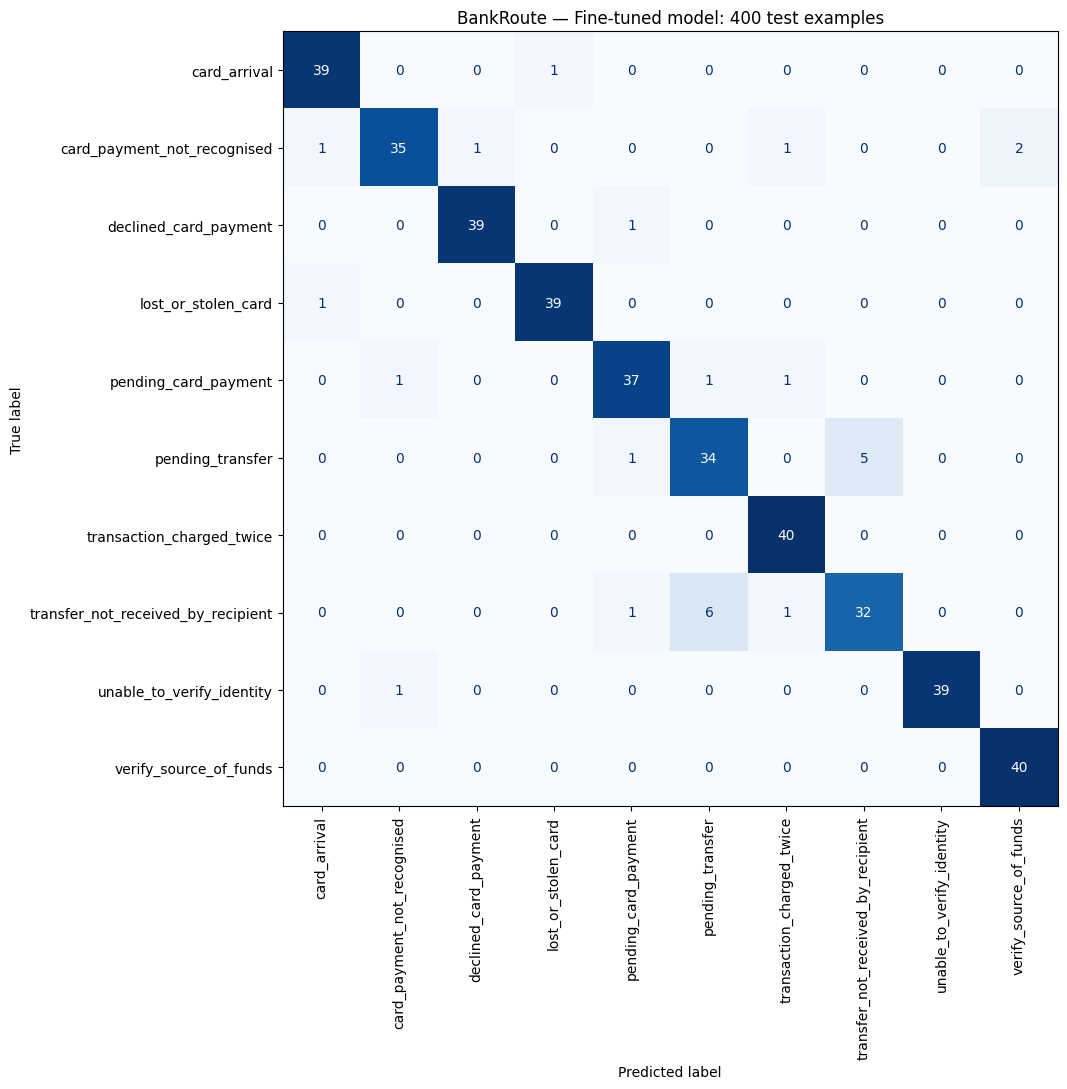

In [ ]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

results = json.loads(
    Path("/content/bankroute_finetuned_test.json").read_text()
)
assert len(results) == 400, "Expected all 400 predictions."

y_true = [row["expected"] for row in results]
y_pred = [row["predicted"] for row in results]
labels = sorted(set(y_true))
assert set(y_pred).issubset(labels), "Unexpected output labels found."

report = classification_report(
    y_true, y_pred, labels=labels, digits=4, zero_division=0
)

print(f"Accuracy: {accuracy_score(y_true, y_pred):.1%}\n")
print(report)

Path("/content/classification_report.txt").write_text(report)

fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax,
)
ax.set_title("BankRoute — Fine-tuned model: 400 test examples")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=150)
plt.show()

## 15. Release the adapter model before loading the baseline

A CPU model occupies several GB of RAM. Release the model references and last generated tensors before loading a separate copy of the original weights. This small memory-management cell was added during cleanup; it has no recorded execution output and does not delete your saved files.


In [ ]:
import gc
import torch

for name in ['model', 'base_model', 'adapter_model', 'inputs', 'output', 'new_tokens']:
    globals().pop(name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print('Previous model references released; saved reports are unchanged.')


## 16. Load the original Qwen3 baseline

Load the same base model without an adapter. This is the original pretrained model, not the merged fine-tuned model. The existing download cache can be reused. The baseline evaluation below must finish before merging the adapter into this object.


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

base_model_id = "Qwen/Qwen3-1.7B-Base"

tokenizer = AutoTokenizer.from_pretrained(base_model_id)

baseline_model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True,
)
baseline_model.eval()

print("READY: original model loaded for baseline evaluation.")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


READY: original model loaded for baseline evaluation.


## 17. Evaluate the baseline on the identical 400 messages

Read the fine-tuned result file to reuse exactly the same messages, labels and ordering. Use the same prompt, greedy decoding, token limit and exact-label scoring. As with fine-tuned evaluation, this cell processes the next 100 examples per execution and saves progress to `bankroute_baseline_test.json`.

The retained final-chunk output records **156/400 = 39.0%**. This measures both intent selection and compliance with the label-only response format. It should not be described as a semantic-only accuracy measurement.


In [ ]:
import json
import torch
from pathlib import Path
from google.colab import files

# Read the exact same 400 messages used for fine-tuned evaluation.
source = Path("/content/bankroute_finetuned_test.json")
assert source.is_file(), "Upload your final 400-result JSON first."

fine_tuned_results = json.loads(source.read_text())
assert len(fine_tuned_results) == 400

intents = [
    "card_arrival", "lost_or_stolen_card",
    "card_payment_not_recognised", "declined_card_payment",
    "pending_card_payment", "transaction_charged_twice",
    "pending_transfer", "transfer_not_received_by_recipient",
    "unable_to_verify_identity", "verify_source_of_funds",
]

instruction = (
    "Classify the banking customer message into exactly one intent. "
    "Return only the intent label, without explanation.\n"
    "Allowed intents: " + ", ".join(intents)
)

path = Path("/content/bankroute_baseline_test.json")
baseline_results = json.loads(path.read_text()) if path.exists() else []

# Check saved progress before resuming.
for i, row in enumerate(baseline_results):
    assert row["message"] == fine_tuned_results[i]["message"]
    assert row["expected"] == fine_tuned_results[i]["expected"]

start = len(baseline_results)
stop = min(start + 100, 400)
baseline_model.eval()

for i in range(start, stop):
    case = fine_tuned_results[i]
    user_text = instruction + "\n\nMessage: " + case["message"]
    prompt = f"Human: {user_text}{tokenizer.eos_token}\nAssistant:"

    inputs = tokenizer(
        prompt, return_tensors="pt", add_special_tokens=False
    ).to(next(baseline_model.parameters()).device)

    with torch.inference_mode():
        output = baseline_model.generate(
            **inputs,
            max_new_tokens=24,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    prediction = tokenizer.decode(
        output[0, inputs["input_ids"].shape[1]:],
        skip_special_tokens=True,
    ).strip()

    baseline_results.append({
        "message": case["message"],
        "expected": case["expected"],
        "predicted": prediction,
        "correct": prediction == case["expected"],
    })

    path.write_text(
        json.dumps(baseline_results, indent=2),
        encoding="utf-8",
    )

    if (i + 1) % 10 == 0:
        print(f"Baseline completed {i + 1}/400", flush=True)

correct = sum(row["correct"] for row in baseline_results)
print(
    f"Baseline accuracy so far: {correct}/{len(baseline_results)}"
    f" = {correct/len(baseline_results):.1%}"
)
files.download(str(path))

Baseline completed 310/400
Baseline completed 320/400
Baseline completed 330/400
Baseline completed 340/400
Baseline completed 350/400
Baseline completed 360/400
Baseline completed 370/400
Baseline completed 380/400
Baseline completed 390/400
Baseline completed 400/400
Baseline accuracy so far: 156/400 = 39.0%


## 18. Compare the original and fine-tuned models

Validate that both final JSON files contain the same 400 messages and labels. Plot per-intent F1 and overall accuracy. Extra or invalid baseline outputs remain errors; the code does not extract labels from explanations. The rightmost bar pair is accuracy, while the other pairs are F1 scores.

The result is **39.0% → 93.5%**, a gain of **54.5 percentage points**. This is not a claim of 100% accuracy, performance across all 77 BANKING77 intents, or production readiness. The chart is saved as `bankroute_baseline_vs_finetuned.png`.


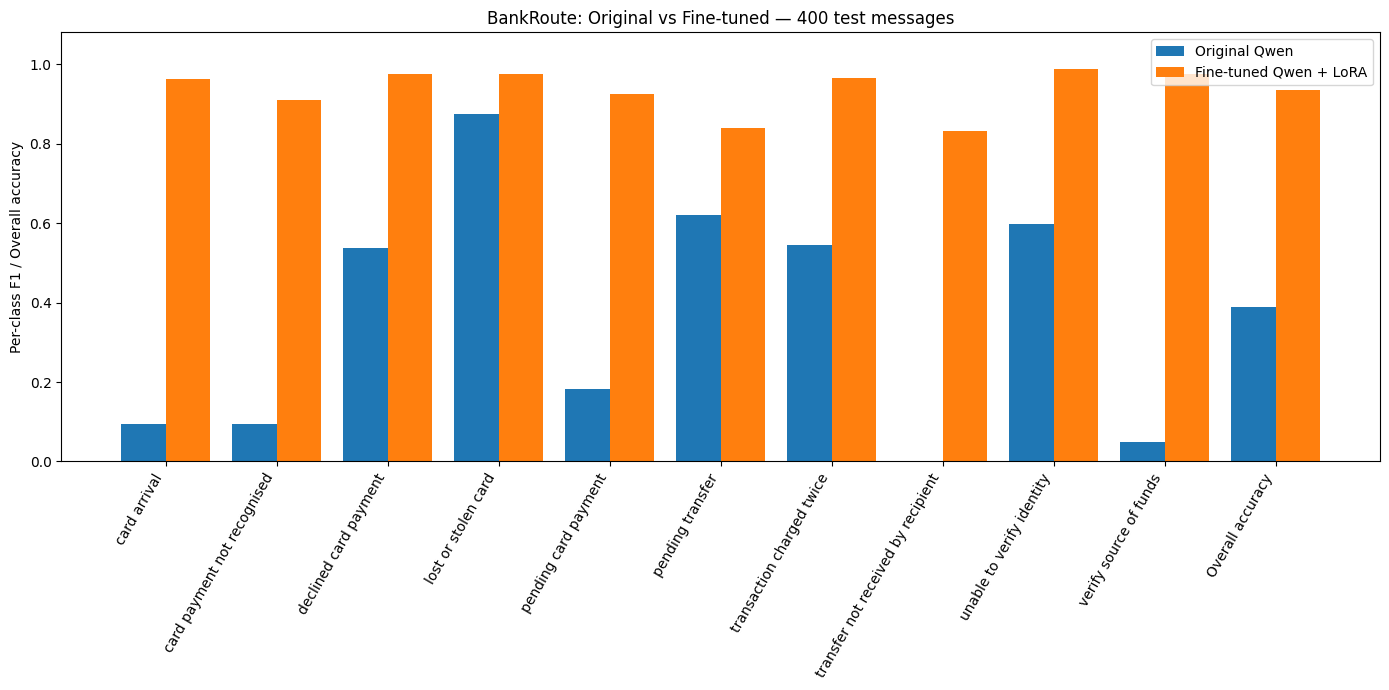

Original accuracy: 39.0%
Fine-tuned accuracy: 93.5%
Improvement: 54.5 percentage points


In [ ]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from google.colab import files

ft_path = Path("/content/bankroute_finetuned_test.json")
base_path = Path("/content/bankroute_baseline_test.json")

assert ft_path.is_file() and base_path.is_file(), \
    "Upload both final JSON files before running this cell."

ft = json.loads(ft_path.read_text())
base = json.loads(base_path.read_text())

assert len(ft) == len(base) == 400

# Confirm both evaluations used the same messages and labels.
assert all(
    a["message"] == b["message"]
    and a["expected"] == b["expected"]
    for a, b in zip(ft, base)
)

y_true = [r["expected"] for r in ft]
ft_pred = [r["predicted"] for r in ft]
base_pred = [r["predicted"] for r in base]
labels = sorted(set(y_true))

ft_f1 = f1_score(
    y_true, ft_pred, labels=labels, average=None, zero_division=0
)
base_f1 = f1_score(
    y_true, base_pred, labels=labels, average=None, zero_division=0
)

ft_acc = accuracy_score(y_true, ft_pred)
base_acc = accuracy_score(y_true, base_pred)

ft_values = list(ft_f1) + [ft_acc]
base_values = list(base_f1) + [base_acc]
display_labels = [x.replace("_", " ") for x in labels]
display_labels += ["Overall accuracy"]

x = np.arange(len(display_labels))
fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(x - 0.2, base_values, width=0.4, label="Original Qwen")
ax.bar(x + 0.2, ft_values, width=0.4, label="Fine-tuned Qwen + LoRA")

ax.set_xticks(x)
ax.set_xticklabels(display_labels, rotation=60, ha="right")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Per-class F1 / Overall accuracy")
ax.set_title("BankRoute: Original vs Fine-tuned — 400 test messages")
ax.legend()
plt.tight_layout()

output = "/content/bankroute_baseline_vs_finetuned.png"
plt.savefig(output, dpi=150)
plt.show()

print(f"Original accuracy: {base_acc:.1%}")
print(f"Fine-tuned accuracy: {ft_acc:.1%}")
print(f"Improvement: {(ft_acc - base_acc) * 100:.1f} percentage points")

files.download(output)

## 19. Plot the training-loss history

Upload the saved `trainer_log.jsonl` or `running_log.txt`. This parser extracts recorded training `loss` values, then plots them in logged order. The horizontal axis is **logged training point**, not epoch or raw optimizer step. It does not plot validation loss.

The retained curve falls from approximately 4.7 to near zero, indicating increasingly accurate training-target prediction. Low training loss alone does not rule out overfitting; the separate official-test evaluation supplies additional evidence. This cell reads a log and does not retrain the model.


Saving running_log.txt to running_log.txt


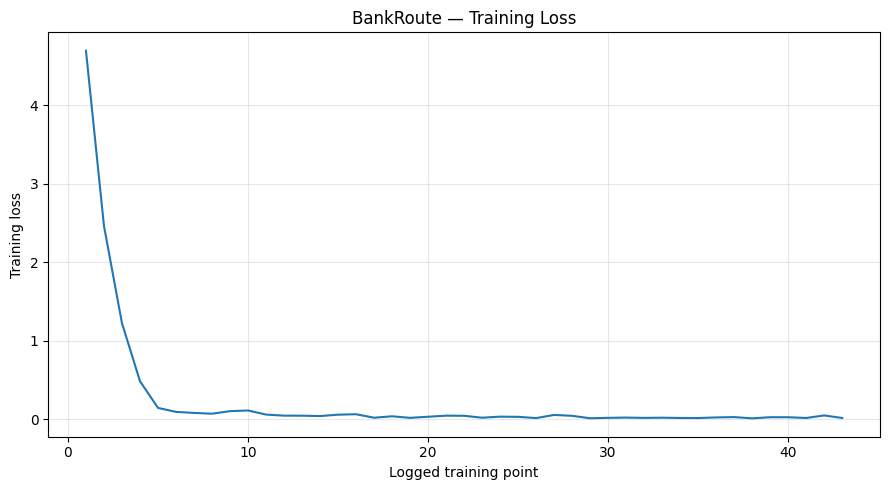

In [ ]:
from google.colab import files
import json
import re
import matplotlib.pyplot as plt

uploaded = files.upload()
filename = next(iter(uploaded))
text = uploaded[filename].decode("utf-8", errors="replace")

losses = []

for line in text.splitlines():
    try:
        record = json.loads(line)
        if isinstance(record, dict) and record.get("loss") is not None:
            losses.append(float(record["loss"]))
            continue
    except (ValueError, TypeError):
        pass

    match = re.search(
        r"""['"]loss['"]\s*:\s*([0-9.eE+-]+)""", line
    )
    if match:
        losses.append(float(match.group(1)))

if not losses:
    print("No training-loss entries found. Share the filename you selected.")
else:
    plt.figure(figsize=(9, 5))
    plt.plot(range(1, len(losses) + 1), losses)
    plt.xlabel("Logged training point")
    plt.ylabel("Training loss")
    plt.title("BankRoute — Training Loss")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    output = "/content/bankroute_training_loss.png"
    plt.savefig(output, dpi=150)
    plt.show()
    files.download(output)

## 20. Confirm the adapter files before merging

Check the two adapter files already restored to `/content/bankroute_adapter`, their sizes, and the base-model name recorded in `adapter_config.json`. The recorded adapter weights are approximately 35 MB. No second upload is needed if Section 9 already restored both files. The original model and tokenizer must be loaded before the merge cell.


In [ ]:
import json
import importlib.util
from pathlib import Path

adapter_dir = Path("/content/bankroute_adapter")

for name in ["adapter_model.safetensors", "adapter_config.json"]:
    path = adapter_dir / name
    print(name, "exists:", path.is_file())
    if path.is_file():
        print("Size:", path.stat().st_size, "bytes")

config_path = adapter_dir / "adapter_config.json"
if config_path.is_file():
    config = json.loads(config_path.read_text())
    print("Base model:", config.get("base_model_name_or_path"))
    print("Adapter type:", config.get("peft_type"))

for package in ["torch", "transformers", "peft"]:
    print(package, "installed:", importlib.util.find_spec(package) is not None)

adapter_model.safetensors exists: True
Size: 34916720 bytes
adapter_config.json exists: True
Size: 1047 bytes
Base model: Qwen/Qwen3-1.7B-Base
Adapter type: LORA
torch installed: True
transformers installed: True
peft installed: True


## 21. Merge the adapter and save a standalone model

Attach the adapter to the original base model, then use `merge_and_unload(safe_merge=True)` to incorporate its updates into the model weights. This removes the need to attach a separate LoRA adapter during subsequent inference. The safe-merge option checks for invalid numerical values; prediction tests remain necessary.

Save the model as sharded safetensors along with the tokenizer and configuration. The recorded output contains **four weight shards totaling approximately 6.9 GB**, stored in `/content/bankroute_merged`. Merging changes the in-memory original model, so do not reuse that object for an unadapted baseline afterward. Keep the original evaluation reports.

For inference, continue using the explicit training-matched prompt in the test below; saving a tokenizer chat-template file does not itself verify that an arbitrary chat interface formats inputs identically.


In [ ]:
from pathlib import Path
from peft import PeftModel

output_dir = Path("/content/bankroute_merged")

assert "baseline_model" in globals(), "Original model is not loaded."
assert "tokenizer" in globals(), "Tokenizer is not loaded."
assert not isinstance(baseline_model, PeftModel), (
    "The model already has an adapter attached. Stop and share this output."
)

print("Attaching the trained adapter...")
adapter_model = PeftModel.from_pretrained(
    baseline_model,
    "/content/bankroute_adapter",
    is_trainable=False,
)
adapter_model.eval()

print("Merging adapter weights...")
merged_model = adapter_model.merge_and_unload(safe_merge=True)
merged_model.eval()

print("Saving model and tokenizer...")
merged_model.save_pretrained(
    output_dir,
    safe_serialization=True,
    max_shard_size="2GB",
)
tokenizer.save_pretrained(output_dir)

print("\nSaved files:")
for path in sorted(output_dir.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size / 1_000_000:.2f} MB")

print("\nMerge and save finished:", output_dir)

Attaching the trained adapter...
Merging adapter weights...
Saving model and tokenizer...



Saved files:
chat_template.jinja: 0.00 MB
config.json: 0.00 MB
generation_config.json: 0.00 MB
model-00001-of-00004.safetensors: 1999.71 MB
model-00002-of-00004.safetensors: 1963.11 MB
model-00003-of-00004.safetensors: 1963.12 MB
model-00004-of-00004.safetensors: 956.39 MB
model.safetensors.index.json: 0.03 MB
tokenizer.json: 11.42 MB
tokenizer_config.json: 0.00 MB

Merge and save finished: /content/bankroute_merged


## 22. Reload the saved standalone model

Release model references and load only from `/content/bankroute_merged`, with `local_files_only=True`. This checks the on-disk model and tokenizer rather than relying solely on the in-memory merged object. No model download or separate adapter attachment occurs. Reading approximately 6.9 GB on CPU can take several minutes.


In [ ]:
import gc
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

for name in [
    "model", "base_model", "baseline_model",
    "adapter_model", "merged_model"
]:
    globals().pop(name, None)

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

saved_path = "/content/bankroute_merged"

tokenizer = AutoTokenizer.from_pretrained(
    saved_path,
    local_files_only=True,
)

merged_model = AutoModelForCausalLM.from_pretrained(
    saved_path,
    local_files_only=True,
    dtype=torch.float32,
    low_cpu_mem_usage=True,
)
merged_model.eval()

print("Saved standalone model loaded successfully.")

Saved standalone model loaded successfully.


## 23. Smoke-test the reloaded banking model

Classify a lost-card message and a pending-payment message using the same explicit prompt and greedy decoding. Both retained predictions match their expected labels and show **PASS**. These two tests confirm basic saved-model functionality; the **93.5% figure belongs to the earlier full adapter-model test**, not to a repeated full evaluation of the merged model.


In [ ]:
import torch

intents = [
    "card_arrival",
    "lost_or_stolen_card",
    "card_payment_not_recognised",
    "declined_card_payment",
    "pending_card_payment",
    "transaction_charged_twice",
    "pending_transfer",
    "transfer_not_received_by_recipient",
    "unable_to_verify_identity",
    "verify_source_of_funds",
]

instruction = (
    "Classify the banking customer message into exactly one intent. "
    "Return only the intent label, without explanation.\n"
    "Allowed intents: " + ", ".join(intents)
)

tests = [
    ("I lost my bank card and cannot find it anywhere.",
     "lost_or_stolen_card"),
    ("My card payment is still pending. When will it finish?",
     "pending_card_payment"),
]

merged_model.eval()

for message, expected in tests:
    user_text = instruction + "\n\nMessage: " + message
    prompt = f"Human: {user_text}{tokenizer.eos_token}\nAssistant:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
    ).to(next(merged_model.parameters()).device)

    with torch.inference_mode():
        output = merged_model.generate(
            **inputs,
            max_new_tokens=24,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    prediction = tokenizer.decode(
        output[0, inputs["input_ids"].shape[1]:],
        skip_special_tokens=True,
    ).strip()

    print("Message:", message)
    print("Prediction:", prediction)
    print("Expected:", expected)
    print("PASS" if prediction == expected else "FAIL")
    print()

Message: I lost my bank card and cannot find it anywhere.
Prediction: lost_or_stolen_card
Expected: lost_or_stolen_card
PASS

Message: My card payment is still pending. When will it finish?
Prediction: pending_card_payment
Expected: pending_card_payment
PASS



## 24. Conclusions and submission evidence

BankRoute adapted Qwen3-1.7B-Base to return one of 10 banking intent labels. LoRA updated a small fraction of the model parameters, while keeping the original base weights frozen during training.

| Evidence | Recorded result |
|---|---|
| Selected training subset | 1,424 examples |
| Training / validation | 1,139 / 285 |
| Official test coverage | 400 messages, 40 per selected intent |
| Original-model exact-label accuracy | 156/400 = 39.0% |
| Fine-tuned exact-label accuracy | 374/400 = 93.5% |
| Accuracy improvement | 54.5 percentage points |
| Fine-tuned macro F1 | 0.9345 |
| Standalone export | Four weight shards plus tokenizer/configuration |
| Reloaded-model smoke tests | 2/2 PASS |

**Limitations:** the task is restricted to 10 known intents. Out-of-scope detection, multilingual performance, realistic workload balance, latency, cost and live ticket routing were not evaluated. The small pilot overlaps the final test split. No full 400-message rerun was performed after merging. Future changes should be developed using training/validation data and evaluated on a fresh untouched test set.

